In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
if 'google.colab' in str(get_ipython()):
    print("Google Colab 環境を検出しました。環境構築を開始します...")
    if not os.path.exists("study-mikanos"):
        !git clone https://github.com/miyayudai/study-mikanos.git
    %cd study-mikanos
    !pip install -q -r requirements.txt
    !pip install -q -e .
    !cmake -B build -S . > /dev/null && cmake --build build --target ch03_kernel_pixel_sim > /dev/null
    print("セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    print("ローカル実行環境です。")


ローカル実行環境です。


# 3.5 カーネルからピクセルを描く (`Drawing Pixels from Kernel`)
## 『ゼロからのOS自作入門』 第3章 画面表示の練習とブートローダ (`osbook_day03c`)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/3/3.5_Drawing_Pixels_from_Kernel.ipynb)

---

### 🎯 本節の学習目標 (Learning Objectives)
1. **ブートローダ主導からカーネル自律への転換**: なぜブートローダ内での描画からカーネル自身による描画へと役割を交代させなければならないのか、そのOSアーキテクチャ上の本質的動機を理解する。
2. **UEFI Boot Services 喪失 (`ExitBootServices`) の影響**: `ExitBootServices` を呼び出した瞬間に UEFI の全 API（`gBS` や GOP 探索関数）が永久に消滅するメカニズムと、カーネルが自立して VRAM (*Video RAM*) を制御するための要件を導出する。
3. **ブートローダからカーネルへの引数引き渡し**: ブートローダが取得したフレームバッファ先頭物理アドレス (`frame_buffer_base`) とサイズ (`frame_buffer_size`) をカーネルエントリポイント (`KernelMain`) に渡す設計を理解する。
4. **ABI (呼出規約) 境界問題と『EFIAPI』省略の奇跡**: UEFI の **Microsoft x64 ABI** (`RCX`, `RDX`) と Linux/ELF カーネルの **System V AMD64 ABI** (`RDI`, `RSI`) のレジスタ衝突を回避し、C言語関数ポインタ宣言からアセンブリスタブ不要で引数が正しく渡る深遠なコンパイラ挙動を解明する。
5. **ピクセル描画アルゴリズムと 256 バイト周期の数理**: `frame_buffer[i] = i % 256` のバイト代入が、なぜ 64 ピクセル周期のカラーストライプや走査線ストライド (*PixelsPerScanLine*) によるモアレ・斜め縞模様を生み出すのかを数理的に完全解剖する。
6. **`HLT` 特権命令と CPU 省電力状態**: カーネル終了時にビジーループ（`while(1);`）ではなく `while(1) __asm__("hlt");` を用いる低レイヤ的・電力工学的必然性を学ぶ。


## 1. なぜカーネルから描画するのか？（ブートローダ主導からカーネル自律への転換）

前節（3.4節 `osbook_day03b`）では、ブートローダ（`BOOTX64.EFI`）の中で UEFI GOP (*Graphics Output Protocol*) を探索し、VRAM (*Video RAM*) の全ピクセルに `0xFF` を書き込むことで画面を白一色に染めることに成功しました。

しかし、これはあくまで**「ブートローダという仮の母体の中で一時的にピクセルを描いてみた」**に過ぎません。

```text
+-----------------------------------------------------------------------------------+
|                        OS 起動シーケンスにおける主権の移譲                        |
+-----------------------------------------------------------------------------------+
|  [ EDK II ブートローダ ]                                                          |
|    - UEFI BIOS の庇護下で動作 (ファームウェア API が使い放題)                     |
|    - ハードウェア検出、メモリマップ取得、ELF カーネルのメモリロード               |
|    - ExitBootServices() を呼んだ瞬間、ブートローダの使命は終了！                  |
|                        |                                                          |
|                        v 制御の移譲 (Jump to Kernel Entry Point)                  |
|  [ MikanOS カーネル (kernel.elf) ]                                                |
|    - ベアメタル (Bare-metal / 裸のハードウェア) 上で独り立ちして動作              |
|    - 以降の画面描画・ウィンドウ管理・GUI 表示はすべてカーネルが担う！            |
+-----------------------------------------------------------------------------------+
```

### 致命的な壁: `ExitBootServices()` 後の世界
ブートローダが OS カーネルへ制御をジャンプさせる直前には、必ず `ExitBootServices()` を呼び出します（3.3節参照）。
この関数を呼んだ瞬間、UEFI ファームウェアは以下のような劇的な状態変化を起こします：
1. **ファームウェア API の全停止**: `gBS->LocateHandleBuffer` や `gBS->OpenProtocol` を含むブートサービス関数群へのポインタはすべて無効化され、呼び出すと CPU 例外（Page Fault や General Protection Fault）が発生します。
2. **UEFI メモリ領域の解放**: `EfiBootServicesCode` や `EfiBootServicesData` 領域は OS によって再利用可能な空きメモリとしてマークされます。
3. **カーネルの孤立無援化**: カーネル内部からは、もはや「UEFI GOP プロトコルを呼び出して画面サイズや VRAM アドレスを教えてもらう」ことは**絶対に不可能**です。

> [!IMPORTANT]
> **本節の核心的命題**:
> カーネルが自律的に画面描画を行うためには、**「ブートローダが生きているうちに UEFI GOP からフレームバッファの物理アドレスとサイズを取得し、カーネル起動時の引数（Arguments）としてカーネルに手渡す」** しか道はありません。


/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:13016: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved figure to: 3/result/fig3_09_bootloader_to_kernel_handoff.png


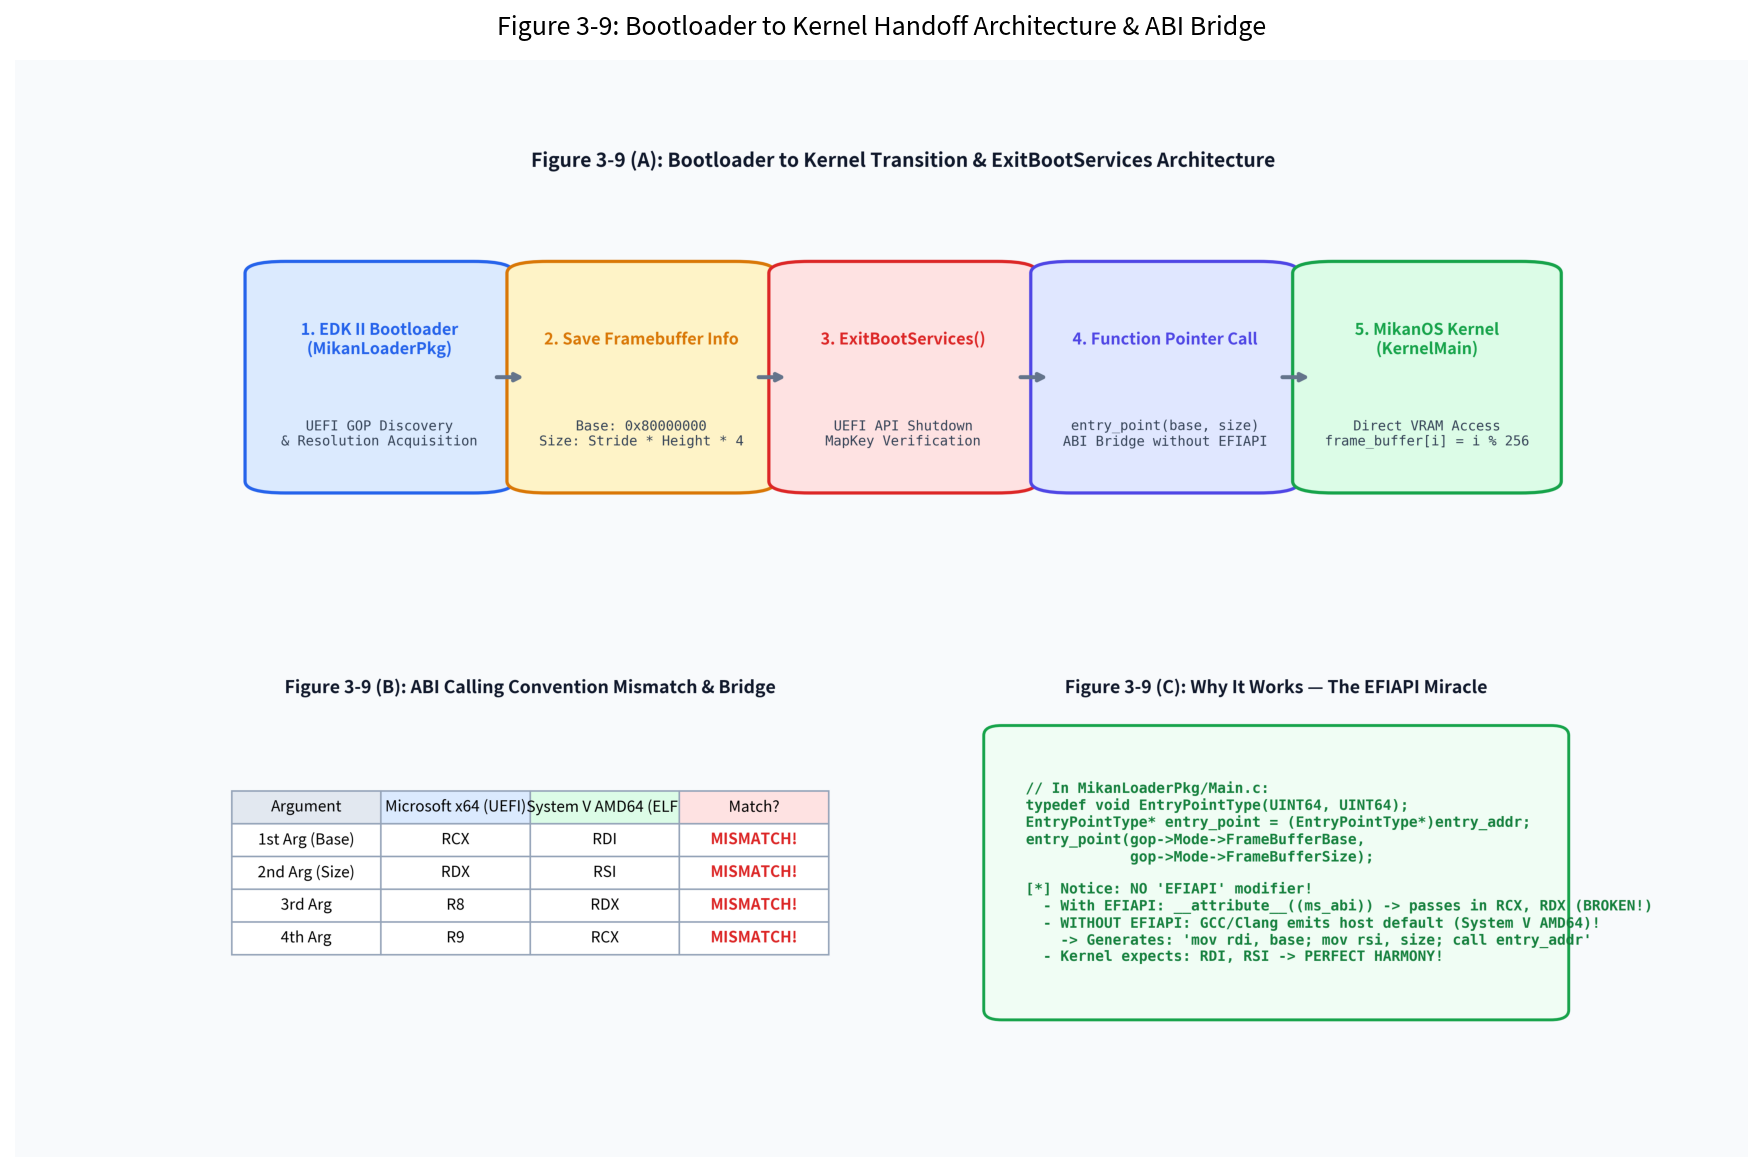

In [2]:
# === ブートローダからカーネルへの制御移譲とABIレジスタ引き渡し構造図 (fig3_09) ===
import matplotlib.pyplot as plt
from PIL import Image
from common import plot_bootloader_to_kernel_handoff

fig9_path = plot_bootloader_to_kernel_handoff("3/result/fig3_09_bootloader_to_kernel_handoff.png")
print("Saved figure to:", fig9_path)

plt.figure(figsize=(15, 9.5), dpi=150)
img = Image.open(fig9_path)
plt.imshow(img)
plt.axis("off")
plt.title("Figure 3-9: Bootloader to Kernel Handoff Architecture & ABI Bridge", fontsize=12, pad=12)
plt.show()


## 2. ブートローダとカーネルの引数受け渡しと ABI 境界問題

カーネルのエントリポイントに関数引数（`frame_buffer_base`, `frame_buffer_size`）を引き渡す際、低レイヤプログラミングにおいて**最も深刻な落とし穴**となるのが **ABI (*Application Binary Interface*, アプリケーションバイナリインターフェース) の不一致**です。

### 呼び出し規約 (*Calling Convention*) の衝突
x86-64 アーキテクチャでは、関数の引数をどの CPU レジスタに格納して渡すかというルール（呼び出し規約）が OS・環境によって真っ二つに分かれています。

| 呼出規約 (Calling Convention) | 採用環境 | 第1引数 | 第2引数 | 第3引数 | 第4引数 | 第5引数 | 第6引数 |
|:---|:---|:---:|:---:|:---:|:---:|:---:|:---:|
| **Microsoft x64 ABI** | Windows / **UEFI EDK II** | `RCX` | `RDX` | `R8` | `R9` | (スタック) | (スタック) |
| **System V AMD64 ABI** | **Linux / ELF / MikanOS** | `RDI` | `RSI` | `RDX` | `RCX` | `R8` | `R9` |

```text
[呼び出し側: UEFI ブートローダ (Microsoft x64 ABI)]
  - 第1引数: RCX = frame_buffer_base (0x80000000)
  - 第2引数: RDX = frame_buffer_size (0x1E0000)

         XXXXX レジスタの不一致 (MISMATCH!) XXXXX

[受け取り側: MikanOS カーネル (System V AMD64 ABI)]
  - 第1引数: RDI から受け取ることを期待！
  - 第2引数: RSI から受け取ることを期待！
```

もしブートローダが Microsoft x64 規約（`RCX`, `RDX`）で値を渡してしまい、カーネルが System V 規約（`RDI`, `RSI`）で値を取り出そうとすると、カーネル側は**未初期化のゴミ値（0 やランダムなアドレス）**を VRAM アドレスとして解釈してしまい、即座にトリプルフォルトやフリーズを引き起こします！

### 『EFIAPI』省略という奇跡のメカニズム
では、MikanOS のブートローダ（`MikanLoaderPkg/Main.c`）はどのようにしてこの ABI の壁を乗り越えたのでしょうか？
`Main.c` の実際のコードを見てみましょう：

```c
// MikanLoaderPkg/Main.c
UINT64 entry_addr = *(UINT64*)(kernel_base_addr + 24);

// ★注目: ここに "EFIAPI" 修飾子が付いていない！
typedef void EntryPointType(UINT64, UINT64);
EntryPointType* entry_point = (EntryPointType*)entry_addr;

entry_point(gop->Mode->FrameBufferBase, gop->Mode->FrameBufferSize);
```

EDK II の UEFI 関数には、通常すべて `EFIAPI` というマクロ修飾子が付与されています：
```c
EFI_STATUS EFIAPI UefiMain(...)
```
Linux 環境で EDK II をビルドする際、GCC や Clang において `EFIAPI` マクロは `__attribute__((ms_abi))` に展開されます。これにより、Linux 上のコンパイラであっても強制的に Microsoft x64 規約のコードを出力します。

しかし！`typedef void EntryPointType(UINT64, UINT64);` には **`EFIAPI` を意図的に付けていません**。
その結果：
1. GCC / Clang は、ホスト環境（Linux）のデフォルト呼出規約である **System V AMD64 ABI** を採用します。
2. コンパイラは、`entry_point(...)` を呼び出す直前に、第1引数を **`RDI`**、第2引数を **`RSI`** に格納する機械語命令を出力します：
   ```nasm
   mov rdi, [gop + 0x18]   ; FrameBufferBase を RDI へ！
   mov rsi, [gop + 0x20]   ; FrameBufferSize を RSI へ！
   call rax                ; entry_point を実行！
   ```
3. カーネル側（`KernelMain`）も System V AMD64 ABI でコンパイルされているため、`RDI` と `RSI` から素直に引数を受け取ります。

こうして、**アセンブリ言語でレジスタを移し替えるラッパーコード（スタブ）を1行も書くことなく、完全な互換性をもって引数が引き渡された**のです！


In [3]:
# === Python による KernelArgumentBridge (ABI ブリッジ) シミュレーション ===
from common import KernelArgumentBridge, CallingConventionKind

base_addr = 0x8000_0000
buffer_size = 1024 * 768 * 4
bridge = KernelArgumentBridge(frame_buffer_base=base_addr, frame_buffer_size=buffer_size)

print("--- 1. Microsoft x64 ABI (EFIAPI ありの場合) ---")
res_ms = bridge.simulate_call(use_efiapi=True)
print("呼び出し側 ABI:", res_ms["caller_abi"].value)
print("設定されたレジスタ:", res_ms["caller_registers"])
print("カーネル側受け取り (RDI, RSI):", f"base=0x{res_ms['received_base']:X}, size=0x{res_ms['received_size']:X}")
print("引数引き渡し成功？:", "SUCCESS" if res_ms["success"] else "FAILED (ゴミ値)")
print("解説:", res_ms["explanation"])

print("\n--- 2. System V AMD64 ABI (EFIAPI 省略の場合: MikanOS の実装) ---")
res_sysv = bridge.simulate_call(use_efiapi=False)
print("呼び出し側 ABI:", res_sysv["caller_abi"].value)
print("設定されたレジスタ:", res_sysv["caller_registers"])
print("カーネル側受け取り (RDI, RSI):", f"base=0x{res_sysv['received_base']:X}, size=0x{res_sysv['received_size']:X}")
print("引数引き渡し成功？:", "SUCCESS" if res_sysv["success"] else "FAILED (ゴミ値)")
print("解説:", res_sysv["explanation"])


--- 1. Microsoft x64 ABI (EFIAPI ありの場合) ---
呼び出し側 ABI: Microsoft x64 ABI (Windows / UEFI Default)
設定されたレジスタ: {'RCX': 2147483648, 'RDX': 3145728, 'R8': 0, 'R9': 0}
カーネル側受け取り (RDI, RSI): base=0x0, size=0x0
引数引き渡し成功？: FAILED (ゴミ値)
解説: EFIAPI修飾子を付与した場合、Microsoft x64 ABI (mov rcx, base; mov rdx, size) で呼び出されるため、カーネル (RDI, RSI) は未定義のゴミ値を受け取り描画が破綻する。

--- 2. System V AMD64 ABI (EFIAPI 省略の場合: MikanOS の実装) ---
呼び出し側 ABI: System V AMD64 ABI (Linux / ELF / MikanOS Kernel)
設定されたレジスタ: {'RDI': 2147483648, 'RSI': 3145728, 'RDX': 0, 'RCX': 0, 'R8': 0, 'R9': 0}
カーネル側受け取り (RDI, RSI): base=0x80000000, size=0x300000
引数引き渡し成功？: SUCCESS
解説: EFIAPI修飾子を省略したため、GCC/Clangはホスト(Linux ELF)の標準であるSystem V AMD64 ABIコード (mov rdi, base; mov rsi, size) を生成。カーネル側の期待レジスタ (RDI, RSI) と完全に一致し、引数が正常に渡る。


## 3. ブートローダ側（Main.c）とカーネル側（main.cpp）の実装差分解説

### カーネル側実装 (`kernel/main.cpp`) の全貌
カーネル側のコードはわずか10行ですが、その中に現代低レイヤ C++ の重要な要素が凝縮されています：

```cpp
#include <cstdint>

extern "C" void KernelMain(uint64_t frame_buffer_base,
                           uint64_t frame_buffer_size) {
  uint8_t* frame_buffer = reinterpret_cast<uint8_t*>(frame_buffer_base);
  for (uint64_t i = 0; i < frame_buffer_size; ++i) {
    frame_buffer[i] = i % 256;
  }
  while (1) __asm__("hlt");
}
```

#### 1. `extern "C"` リンケージ指定
C++ コンパイラは通常、関数のオーバーロードを可能にするためにシンボル名をマングル（*Name Mangling*）します（例: `_Z10KernelMainmm`）。
しかしブートローダ側は ELF ヘッダのエントリポイントアドレス（ELFヘッダ先頭から24バイト目の値）を直に呼び出します。将来的にシンボル名解決を行う際にも名前が壊れないよう、`extern "C"` を付与して C 言語形式のシンボル（`KernelMain`）としてエクスポートします。

#### 2. `reinterpret_cast<uint8_t*>` によるポインタ復元
引数 `frame_buffer_base` は 64 ビット符号なし整数（`uint64_t`）として渡されます。
CPU はこの整数値をそのままメモリアドレスとして解釈するため、C++ の型安全性キャストである `reinterpret_cast<uint8_t*>` を用いてバイト単位のポインタへと変換します。

#### 3. `while (1) __asm__("hlt");` (HLT 特権命令)
描画が完了した後、OS は何をすべきでしょうか？
この時点ではまだ割り込みハンドラもマルチタスクもキーボードドライバもありません。プログラムを終了させてしまうと CPU はメモリ上の未定義な命令を暴走実行してしまいます。

そこで無限ループで停止させるのですが、単なる `while (1);`（ビジーループ）にしてしまうと、CPU コアが 100% のクロック周波数で無駄に電力を消費し、発熱してしまいます。

```nasm
.loop:
    hlt          ; CPU を低電力スリープ状態にし、外部割り込みが来るまで停止
    jmp .loop    ; 割り込みから復帰したら再び HLT
```

> [!NOTE]
> **`HLT` 命令の特権レベル**:
> `HLT` 命令は x86 アーキテクチャにおける**特権命令（Privileged Instruction）**です。
> CPU が最高特権レベルである **Ring 0（カーネルモード）** で動作している時のみ実行が許可されています。将来アプリ空間（Ring 3 ユーザーモード）でアプリが勝手に `HLT` を実行した場合は、即座に `#GP` (*General Protection Fault*, 一般保護例外) が発生して OS に強制終了されます。


/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:13162: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved figure to: 3/result/fig3_10_kernel_pixel_stripe_pattern.png


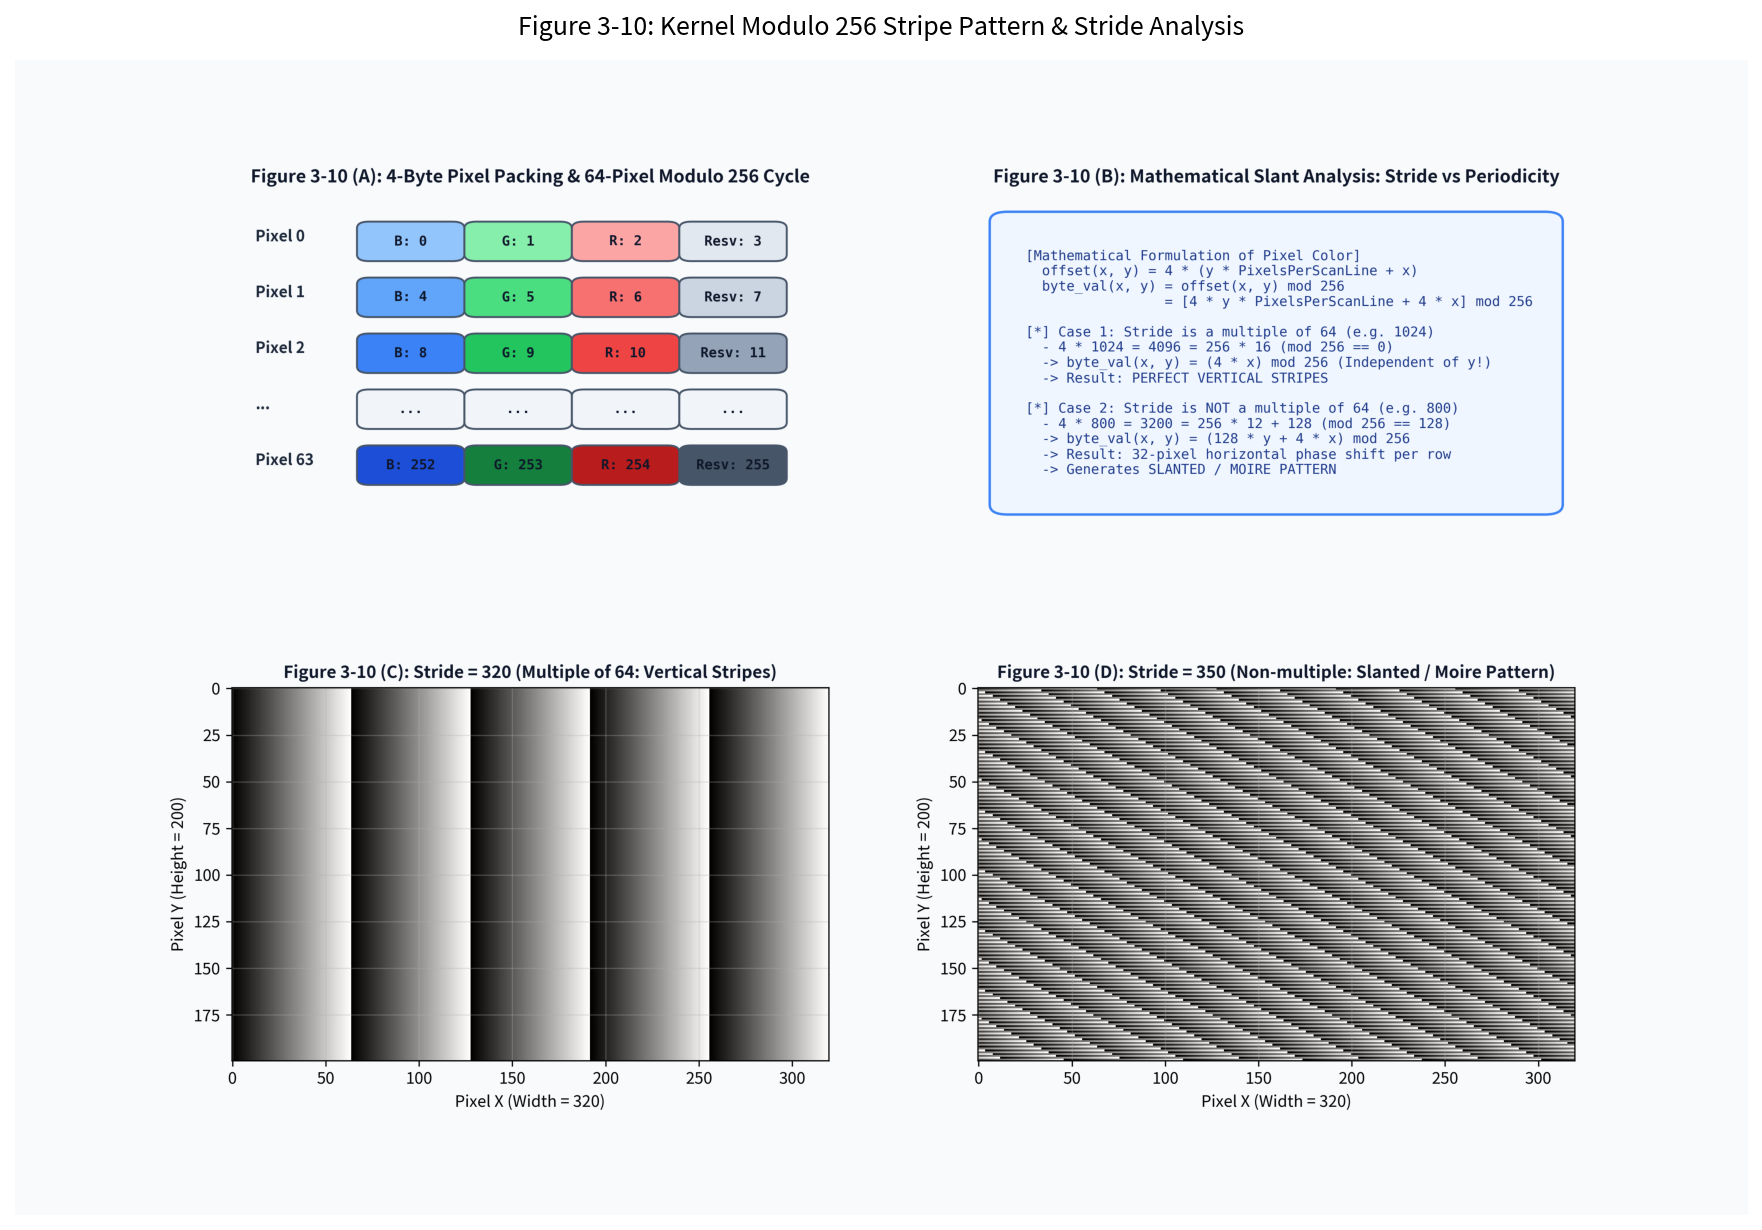

In [4]:
# === ピクセルバイト配置とストライプ・モアレ描画再現図 (fig3_10) ===
import matplotlib.pyplot as plt
from PIL import Image
from common import plot_kernel_pixel_stripe_pattern

fig10_path = plot_kernel_pixel_stripe_pattern("3/result/fig3_10_kernel_pixel_stripe_pattern.png")
print("Saved figure to:", fig10_path)

plt.figure(figsize=(15, 10.0), dpi=150)
img = Image.open(fig10_path)
plt.imshow(img)
plt.axis("off")
plt.title("Figure 3-10: Kernel Modulo 256 Stripe Pattern & Stride Analysis", fontsize=12, pad=12)
plt.show()


## 4. ピクセル描画アルゴリズムと 256 バイト周期の数理（カラーストライプとモアレ）

カーネルの描画ループ：
$$\text{frame\_buffer}[i] = i \pmod{256}$$
は、一見するとただの単純なテスト書き込みに見えます。しかし、画面上には**非常に美しく複雑なグラデーションの縞模様（ストライプ）**が現れます。この現象を数理的に解き明かしましょう。

### 4バイトピクセルパッキングと 64 ピクセル周期
第3.4節で学んだ通り、UEFI GOP の標準ピクセルフォーマットは 1 ピクセルあたり 4 バイト（32 ビット）です。
一般的な PC や QEMU では `PixelBlueGreenRedReserved8BitPerColor`（BGRR）が採用されています。

メモリ上のバイト列を 4 バイト（1 ピクセル）ごとに区切ると、各ピクセルの色は以下のように決定されます：

| ピクセル | バイトオフセット | Byte 0 (Blue) | Byte 1 (Green) | Byte 2 (Red) | Byte 3 (Resv) | RGB 表現 |
|:---:|:---:|:---:|:---:|:---:|:---:|:---:|
| **Pixel 0** | $0 \sim 3$ | $0$ | $1$ | $2$ | $3$ | $(R=2, G=1, B=0)$ |
| **Pixel 1** | $4 \sim 7$ | $4$ | $5$ | $6$ | $7$ | $(R=6, G=5, B=4)$ |
| **Pixel 2** | $8 \sim 11$ | $8$ | $9$ | $10$ | $11$ | $(R=10, G=9, B=8)$ |
| $\dots$ | $\dots$ | $\dots$ | $\dots$ | $\dots$ | $\dots$ | $\dots$ |
| **Pixel 63** | $252 \sim 255$ | $252$ | $253$ | $254$ | $255$ | $(R=254, G=253, B=252)$ |
| **Pixel 64** | $256 \sim 259$ | **$0$** | **$1$** | **$2$** | **$3$** | **$(R=2, G=1, B=0)$** |

$$256 \text{ バイト} \div 4 \text{ バイト/ピクセル} = 64 \text{ ピクセル}$$
すなわち、**64 ピクセル進むごとに、まったく同一のピクセル色パターンが完全に一巡（ループ）** します！

---

### 走査線ストライド (*PixelsPerScanLine*) と縞模様の幾何学
では、画面全体を見たときに「垂直の縦縞」に見えるのか、「斜めの縞模様（モアレ）」に見えるのかは何によって決まるのでしょうか？

座標 $(x, y)$ のバイトオフセットは以下の式で表されます：
$$\text{offset}(x, y) = 4 \times (y \times \text{PixelsPerScanLine} + x)$$

このオフセットに書き込まれる値は $\text{offset}(x, y) \pmod{256}$ です：
$$\text{val}(x, y) = [4 \times y \times \text{PixelsPerScanLine} + 4 \times x] \pmod{256}$$

#### ケース 1: ストライドが 64 の倍数の場合（例: 1024, 640）
$$\text{PixelsPerScanLine} = 1024 \implies 4 \times 1024 = 4096 = 256 \times 16 \equiv 0 \pmod{256}$$
このとき、$y$ の項は $256$ で割り切れて完全に消滅します！
$$\text{val}(x, y) = 4x \pmod{256}$$
値が $y$（垂直座標）に一切依存しなくなるため、**すべての行で全く同じ $X$ 座標に同じ色が並び、完全な「垂直縦縞（Pure Vertical Stripes）」** が現れます！

#### ケース 2: ストライドが 64 の倍数ではない場合（例: 800）
$$\text{PixelsPerScanLine} = 800 \implies 4 \times 800 = 3200 = 256 \times 12 + 128 \equiv 128 \pmod{256}$$
$$\text{val}(x, y) = [128y + 4x] \pmod{256}$$
行が 1 つ進む（$y$ が 1 増える）ごとに、オフセット位相が $128$ バイト（$= 32$ ピクセル）ずつ水平にズレていきます！
その結果、偶数行と奇数行で位相が半周期（32ピクセル）反転し、**画面全体に美しい「斜め縞模様・チェッカーモアレパターン」** が形成されるのです！


In [5]:
# === Python によるストライド幾何学解析とピクセル色分解 ===
from common import MikanKernelDrawer, UefiGraphicsPixelFormat

print("=== ストライド周期性解析 (Stride Periodicity Analysis) ===")
for test_stride in [640, 800, 1024, 1366]:
    drawer = MikanKernelDrawer(width=test_stride, height=600, pixels_per_scan_line=test_stride)
    info = drawer.analyze_stride_periodicity()
    print(f"\n[Stride = {test_stride}]")
    print(f"  - 1行のバイト数: {test_stride * 4} Bytes")
    print(f"  - 256で割った余り: {info['stride_byte_mod']} Bytes ({info['line_shift_pixels']} ピクセル)")
    print(f"  - パターン種別: {info['pattern_type']}")

print("\n=== ピクセル色分解 (Pixel Color Packing: Pixel 0 〜 2, 63, 64) ===")
drawer_demo = MikanKernelDrawer(width=800, height=600, pixels_per_scan_line=800,
                               pixel_format=UefiGraphicsPixelFormat.PixelBlueGreenRedReserved8BitPerColor)
drawer_demo.execute_modulo256()

for p in [0, 1, 2, 63, 64]:
    b0, b1, b2, b3 = drawer_demo.get_pixel_bytes(p, 0)
    r, g, b = drawer_demo.get_pixel_rgb(p, 0)
    print(f"Pixel #{p:2d}: Raw Bytes=(B:{b0:3d}, G:{b1:3d}, R:{b2:3d}, Resv:{b3:3d}) -> RGB=({r:3d}, {g:3d}, {b:3d})")


=== ストライド周期性解析 (Stride Periodicity Analysis) ===

[Stride = 640]
  - 1行のバイト数: 2560 Bytes
  - 256で割った余り: 0 Bytes (0 ピクセル)
  - パターン種別: 完全な垂直縦縞 (Pure Vertical Stripes)

[Stride = 800]
  - 1行のバイト数: 3200 Bytes
  - 256で割った余り: 128 Bytes (32 ピクセル)
  - パターン種別: 斜め縞 / モアレ模様 (Slanted Stripes / Moire, 行シフト: 32 ピクセル/行)

[Stride = 1024]
  - 1行のバイト数: 4096 Bytes
  - 256で割った余り: 0 Bytes (0 ピクセル)
  - パターン種別: 完全な垂直縦縞 (Pure Vertical Stripes)

[Stride = 1366]
  - 1行のバイト数: 5464 Bytes
  - 256で割った余り: 88 Bytes (22 ピクセル)
  - パターン種別: 斜め縞 / モアレ模様 (Slanted Stripes / Moire, 行シフト: 22 ピクセル/行)

=== ピクセル色分解 (Pixel Color Packing: Pixel 0 〜 2, 63, 64) ===
Pixel # 0: Raw Bytes=(B:  0, G:  1, R:  2, Resv:  3) -> RGB=(  2,   1,   0)
Pixel # 1: Raw Bytes=(B:  4, G:  5, R:  6, Resv:  7) -> RGB=(  6,   5,   4)
Pixel # 2: Raw Bytes=(B:  8, G:  9, R: 10, Resv: 11) -> RGB=( 10,   9,   8)
Pixel #63: Raw Bytes=(B:252, G:253, R:254, Resv:255) -> RGB=(254, 253, 252)
Pixel #64: Raw Bytes=(B:  0, G:  1, R:  2, Resv:  3) -> RGB=(  2,   1,

## 5. 対話型 C++20 検証コードの実行

MikanOS カーネルの核となる `KernelMain`、System V AMD64 ABI レジスタ整合性、およびストライド周期性解析を、ホスト側の C++20 スタンドアロンコード（`src/ch03/kernel_pixel_sim.cpp`）としてコンパイル・実行し、すべての動作要件を満たしていることを検証します。


In [6]:
# === C++20 スタンドアロン検証コードのビルドとテスト実行 ===
import subprocess

# CMake でターゲットをビルド
build_res = subprocess.run(["cmake", "--build", "build", "--target", "ch03_kernel_pixel_sim"],
                           capture_output=True, text=True)
print(build_res.stdout)
if build_res.returncode != 0:
    print("Build Error:", build_res.stderr)

# 検証バイナリの実行
run_res = subprocess.run(["./build/bin/ch03_kernel_pixel_sim"], capture_output=True, text=True)
print(run_res.stdout)
assert run_res.returncode == 0, "C++20 検証に失敗しました！"


[100%] Built target ch03_kernel_pixel_sim

 MikanOS Chapter 3.5: Kernel Pixel Simulation (day03c)  

[PASS] ABI Calling Convention Bridge Test
[PASS] Simulated KernelMain Execution Test
[PASS] Stride Geometry and Moire Analysis Test

--------------------------------------------------------
 ABI Handoff & Register Verification Summary:          
--------------------------------------------------------
 Bootloader (EDK II): Caller omitted EFIAPI modifier   
 Code generated     : mov rdi, base; mov rsi, size     
 Kernel (ELF / C++) : KernelMain(rdi, rsi)             
 Status             : Seamless Register Compatibility! 
 Pattern Cycle      : 256 Bytes / 64 Pixels per Period 
 Stride Geometry    : 1024 -> Pure Vertical Stripes    
                      800  -> Slanted Moire (32px shift)
--------------------------------------------------------
[SUCCESS] All Chapter 3.5 C++20 verifications passed!



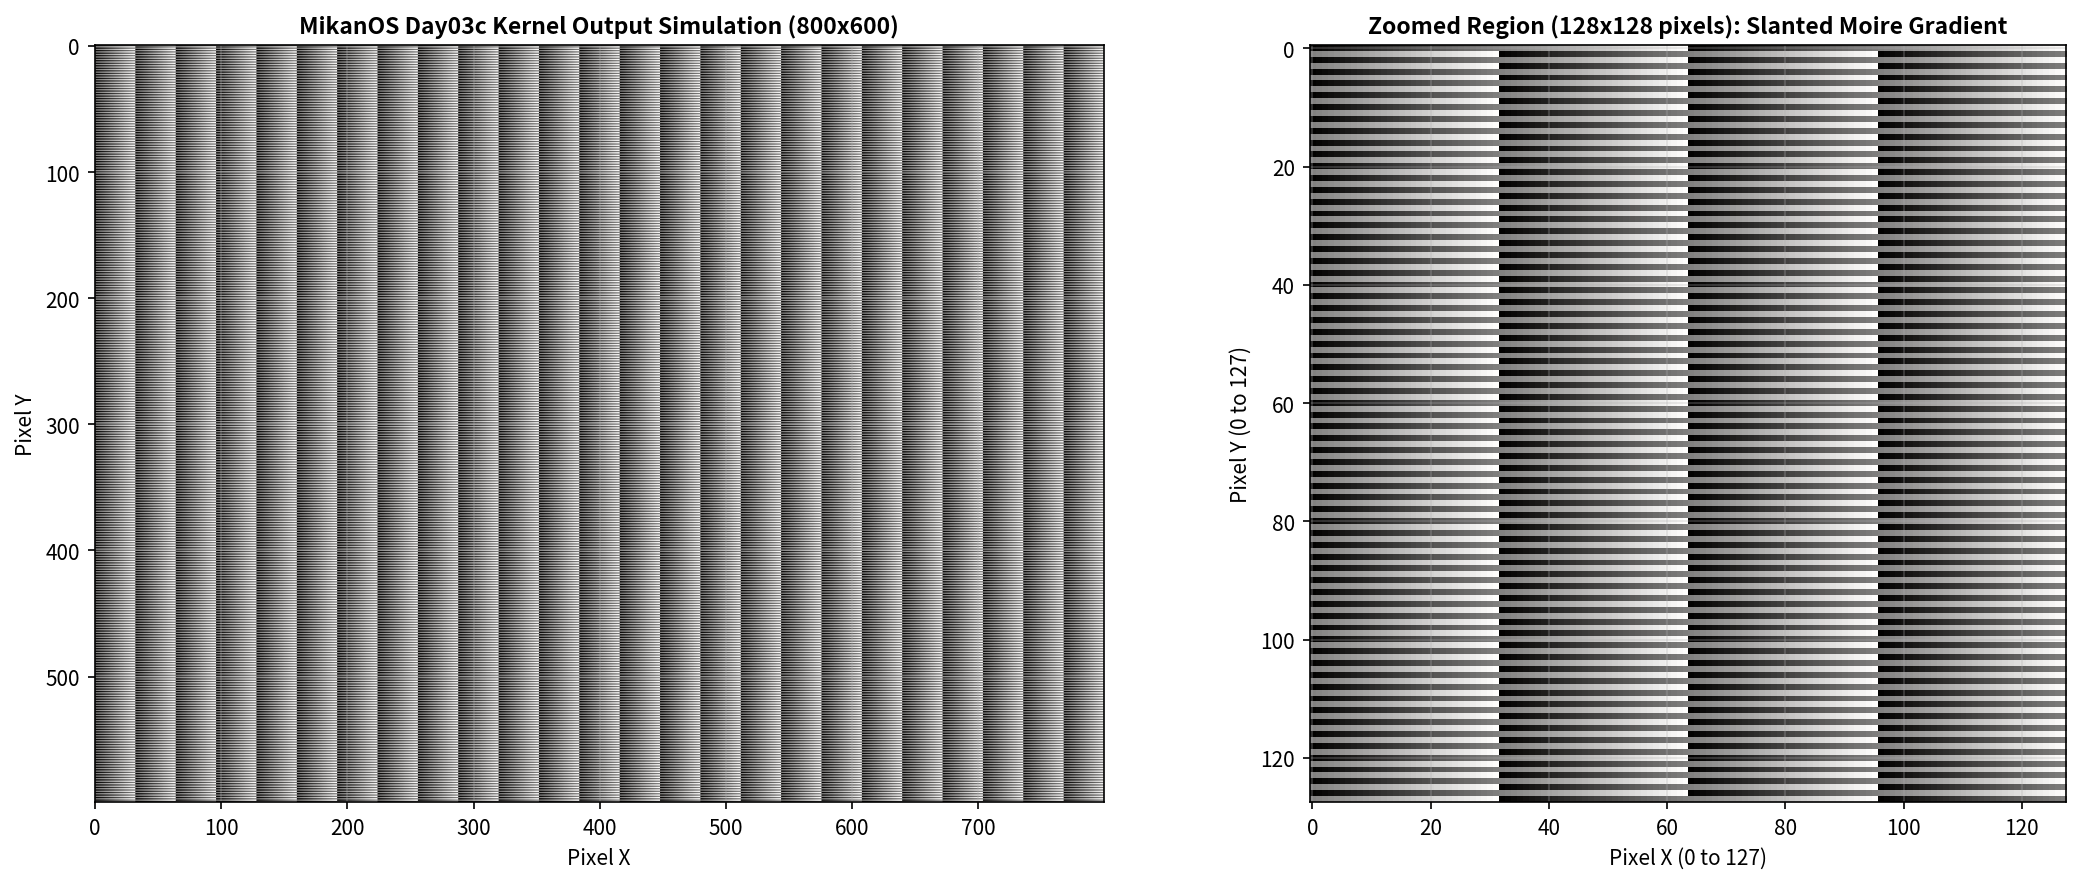

QEMU 実機画面と同等のフレームバッファ描画が正常に完了しました！


In [7]:
# === Python MikanKernelDrawer による QEMU 画面のピクセル完全再現描画 ===
import matplotlib.pyplot as plt
from common import MikanKernelDrawer, UefiGraphicsPixelFormat

# QEMU デフォルト標準解像度: 800 x 600 (BGRR)
qemu_drawer = MikanKernelDrawer(width=800, height=600, pixels_per_scan_line=800,
                                pixel_format=UefiGraphicsPixelFormat.PixelBlueGreenRedReserved8BitPerColor)
qemu_drawer.execute_modulo256()

# フレームバッファから画面用 NumPy 配列を生成
screen_img = qemu_drawer.render_to_numpy_array()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), dpi=150)

# 全画面描画
ax1.imshow(screen_img)
ax1.set_title("MikanOS Day03c Kernel Output Simulation (800x600)", fontsize=11, fontweight="bold")
ax1.set_xlabel("Pixel X")
ax1.set_ylabel("Pixel Y")

# 左上 128x128 領域の拡大（斜め縞・モアレ模様の微細構造）
ax2.imshow(screen_img[:128, :128])
ax2.set_title("Zoomed Region (128x128 pixels): Slanted Moire Gradient", fontsize=11, fontweight="bold")
ax2.set_xlabel("Pixel X (0 to 127)")
ax2.set_ylabel("Pixel Y (0 to 127)")

plt.tight_layout()
plt.show()
print("QEMU 実機画面と同等のフレームバッファ描画が正常に完了しました！")


## 6. 本節のまとめと次章への展望

### 🏆 到達した成果 (Milestones Achieved)
1. **ブートローダからの自立**: UEFI Boot Services 終了後、カーネルが自らのコードで VRAM MMIO アドレス空間へ直接アクセスし、画面全体を描画することに成功しました。
2. **ABI ブリッジの解明**: Microsoft x64 ABI (`RCX`, `RDX`) と System V AMD64 ABI (`RDI`, `RSI`) の衝突を、関数ポインタ宣言における `EFIAPI` 省略によって Clang/GCC に System V コードを生成させることで解決する洗練された仕組みを学びました。
3. **ストライプ・モアレの数理**: 1 ピクセル 4 バイトと `i % 256` の合同式から、64 ピクセルの一巡周期と、走査線ストライド（800 や 1024）による幾何学的縞模様の発生メカニズムを数式とシミュレーションで証明しました。
4. **`HLT` 命令の役割**: CPU を無限ループで空回しさせるのではなく、Ring 0 特権命令である `HLT` を用いて省電力待機させるOS設計の基本を習得しました。

---

### 🚀 次のステップ: 第3章 3.6 エラー処理をしよう (`osbook_day03d`)
現在のブートローダは、メモリマップ保存やカーネル読み込みが失敗した場合の「エラー処理」がほとんど行われておらず、何か 1 つでも失敗すると沈黙してしまいます。
次節では、`EFI_STATUS` による堅牢なエラーハンドリング機構を導入し、ポインタのキャスト（コラム3.2: `reinterpret_cast`）の深層に迫ります！
